[Sommaire](00_sommaire.ipynb) · ⬅ [Thème 6 — Préfixes, dichotomie, tri](theme6_prefixes_dichotomie_tri.ipynb) · [Thème 8 — Programmation dynamique](theme8_dp_backtracking.ipynb) ➡

# Thème 7 — Mathématiques et algorithmes gloutons

**Dans ce notebook, tu vas apprendre :**
- utiliser `//` et `%` pour découper un nombre, compter sans boucle et « tourner en rond » ;
- calculer un PGCD avec l'algorithme d'Euclide, et comprendre pourquoi il est si rapide ;
- ce qu'est un algorithme **glouton**, quand il marche… et comment vérifier qu'il ne se trompe pas.

**Prérequis :** thèmes 0 et 6 (notation O, tri avec une clé)

> Exécute d'abord la cellule ci-dessous : elle contient l'outil `verifier`, qui teste automatiquement ta solution dans l'exercice final.

In [ ]:
# Outil utilisé dans l'exercice « À toi de jouer » de ce notebook.
# Il appelle ta fonction sur plusieurs cas et affiche ✅ (bon), ❌ (mauvais) ou 💥 (plantage).
# Tu n'as pas besoin de comprendre ce code pour t'en servir : exécute simplement cette cellule.

import copy

def verifier(fonction, cas):
    reussis = 0
    for arguments, attendu in cas:
        texte_args = ", ".join(repr(a) for a in arguments)
        try:
            obtenu = fonction(*copy.deepcopy(arguments))
        except Exception as erreur:
            print(f"💥 {fonction.__name__}({texte_args}) a planté : {type(erreur).__name__}: {erreur}")
            continue
        if obtenu == attendu:
            reussis += 1
            print(f"✅ {fonction.__name__}({texte_args}) -> {obtenu!r}")
        else:
            print(f"❌ {fonction.__name__}({texte_args}) -> {obtenu!r}   (attendu : {attendu!r})")
    print(f"\n{reussis}/{len(cas)} tests réussis")

## Partie 1 — Les outils de calcul : `//` et `%`

### Le problème de départ
> Combien y a-t-il de multiples de 7 entre 1 et 10¹² ?

Une boucle qui teste chaque nombre ferait 10¹² tours. À 10 millions d'opérations par seconde (thème 0), il faudrait plus d'une journée. Un peu d'arithmétique répond en **une seule opération**.

### Le concept : le partage des bonbons
On partage 17 bonbons entre 5 enfants, à parts égales. Chaque enfant en reçoit **3**, et il en reste **2** dans le sac.
- `17 // 5` vaut `3` : le **quotient**, c'est-à-dire le nombre de parts complètes (on parle de « division entière ») ;
- `17 % 5` vaut `2` : le **reste** (on dit « 17 modulo 5 »).

Et c'est toujours vrai : `17 == 3 * 5 + 2`. En général : `a == (a // b) * b + a % b`.

| Je veux… | Code | Exemple |
|---|---|---|
| le nombre de parts complètes | `a // b` | `17 // 5` → 3 |
| ce qui reste | `a % b` | `17 % 5` → 2 |
| savoir si `a` est divisible par `b` | `a % b == 0` | `15 % 5 == 0` → True |
| savoir si `x` est pair | `x % 2 == 0` | `8 % 2 == 0` → True |
| le dernier chiffre de `n` | `n % 10` | `4572 % 10` → 2 |
| enlever le dernier chiffre | `n // 10` | `4572 // 10` → 457 |
| compter les multiples de `k` entre 1 et `x` | `x // k` | `20 // 3` → 6 (3, 6, 9, 12, 15, 18) |
| tourner en rond (jours, horloge, liste circulaire) | `(i + pas) % n` | `(5 + 4) % 7` → 2 |

## On manipule

In [ ]:
print(17 // 5, 17 % 5)            # 3 2 : 17 = 3 × 5 + 2

# Convertir une durée en heures, minutes, secondes
duree = 5000                      # en secondes
heures = duree // 3600            # nombre d'heures complètes
reste = duree % 3600              # les secondes qui restent une fois les heures retirées
minutes = reste // 60
secondes = reste % 60
print(heures, minutes, secondes)  # 1 23 20
print(divmod(5000, 3600))         # (1, 1400) : le quotient et le reste d'un coup

# Compter sans boucle
print(20 // 3)                                        # 6 multiples de 3 entre 1 et 20
print(len([i for i in range(1, 21) if i % 3 == 0]))   # 6 aussi, vérifié avec une boucle
print(10**12 // 7)                                    # 142857142857, instantanément

# Tourner en rond : quel jour serons-nous dans 1000 jours, si aujourd'hui est un lundi ?
jours = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
print(jours[(0 + 1000) % 7])      # dimanche : 1000 jours = 142 semaines complètes + 6 jours

### Découper un nombre en chiffres
`n % 10` donne le dernier chiffre, `n // 10` l'enlève. En répétant les deux, on récupère tous les chiffres, de droite à gauche.

**Trace à la main** sur 4572 :

| `n` | `n % 10` (chiffre récupéré) | `n // 10` (ce qui reste) |
|---|---|---|
| 4572 | 2 | 457 |
| 457 | 7 | 45 |
| 45 | 5 | 4 |
| 4 | 4 | 0 → on s'arrête |

In [ ]:
def chiffres(n):
    resultat = []
    while n > 0:
        resultat.append(n % 10)   # le dernier chiffre
        n //= 10                  # on l'enlève
    return resultat               # attention : de droite à gauche !

print(chiffres(4572))             # [2, 7, 5, 4]
print(chiffres(0))                # [] : pourtant, 0 a bien un chiffre !

# Souvent plus simple : passer par le texte
print([int(c) for c in str(4572)])   # [4, 5, 7, 2], dans l'ordre de lecture
print(len(str(0)))                   # 1 : str(0) vaut "0", un chiffre

### Les pièges de la division en Python

In [ ]:
print(7 / 2)                # 3.5 : « / » donne TOUJOURS un nombre à virgule (un float)
print(7 // 2)               # 3   : « // » donne un entier

print(-7 // 2, -7 % 2)      # -4 1 : Python arrondit toujours vers le BAS (−3,5 → −4)

print(10**18 // 3)          # 333333333333333333 : exact
print(int(10**18 / 3))      # 333333333333333312 : faux ! un float ne garde qu'environ 16 chiffres exacts

Règle : pour un calcul sur des entiers, utilise `//`, jamais `/` suivi de `int(…)`.

### Le PGCD et l'algorithme d'Euclide
> On veut carreler une pièce rectangulaire de 48 × 18 avec des dalles **carrées**, toutes identiques, **les plus grandes possible**, sans en couper aucune. Quelle taille de dalle ?

La réponse est le **PGCD** (plus grand commun diviseur) de 48 et 18 : le plus grand nombre qui divise les deux. Il sert aussi à simplifier une fraction : 48/18 = (48 ÷ 6) / (18 ÷ 6) = 8/3.

**Approche naïve** : essayer tous les nombres de `min(a, b)` jusqu'à 1, et garder le premier qui divise les deux. C'est O(min(a, b)) : beaucoup trop lent pour des nombres de l'ordre de 10¹².

**L'idée d'Euclide**, avec le rectangle : on pose dans le rectangle 48 × 18 autant de grands carrés 18 × 18 que possible. Il en tient 2 (`48 // 18`), et il reste une bande de 12 × 18 (`48 % 18` vaut 12). Une dalle qui carrèle parfaitement le grand rectangle doit aussi carreler cette bande : on recommence donc avec le rectangle 18 × 12, plus petit. Et ainsi de suite, jusqu'à ce qu'il ne reste plus rien.

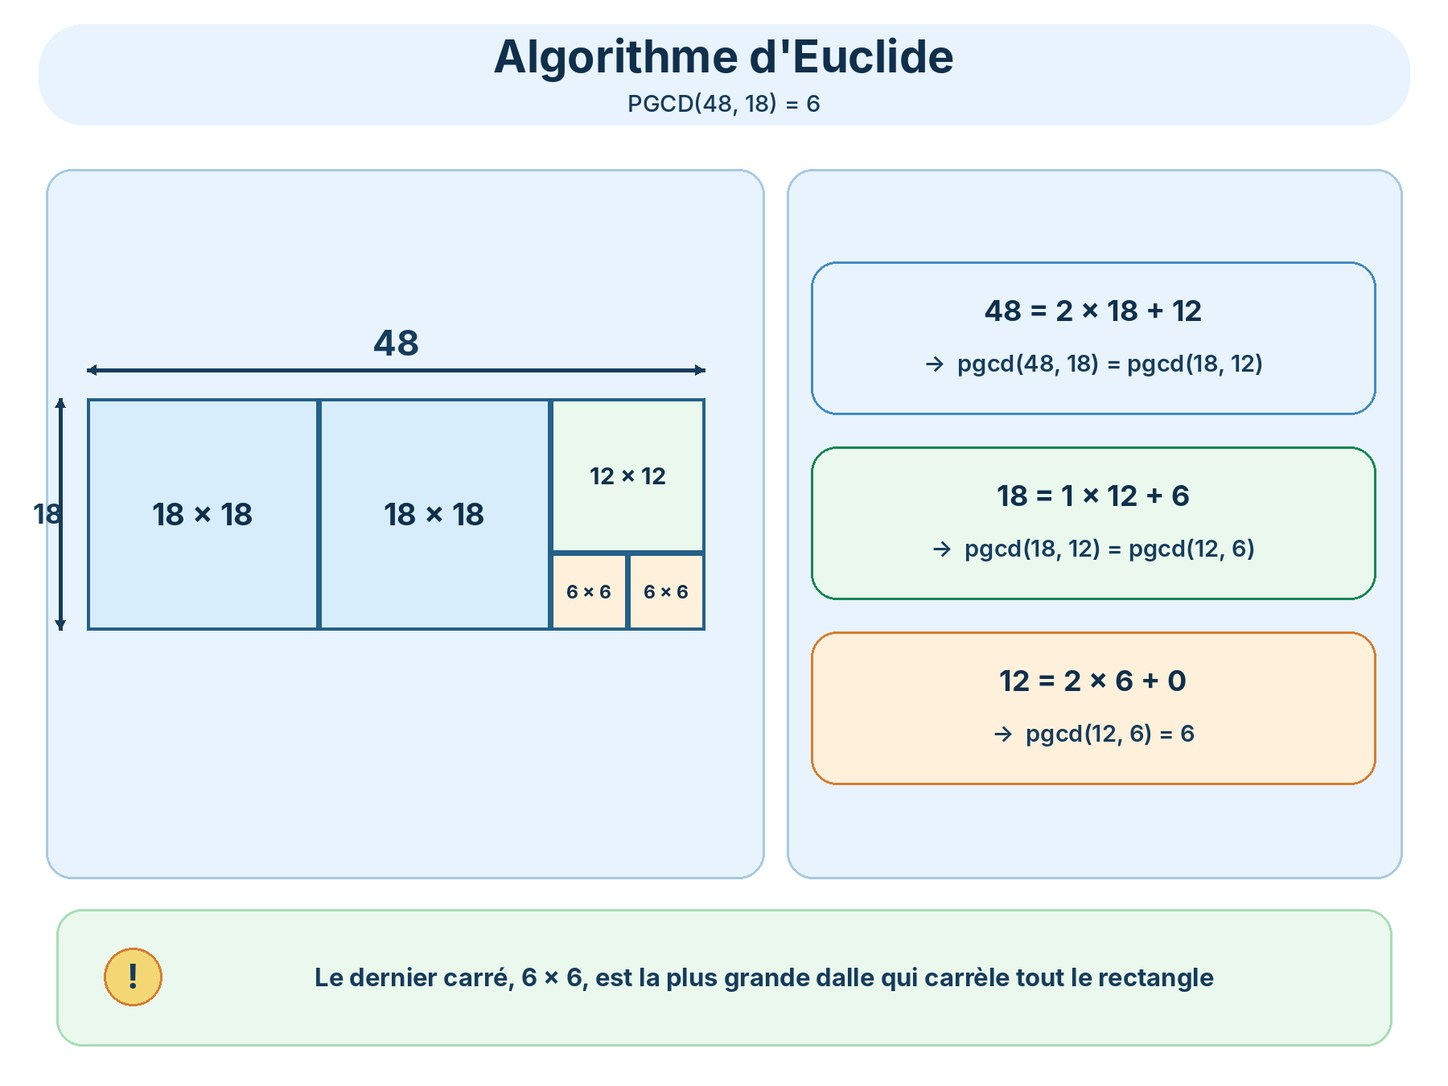

Sur l'image : dans le rectangle 48 × 18, on place 2 carrés de 18, il reste une bande 18 × 12 ; dans cette bande, 1 carré de 12, il reste 12 × 6 ; dans ce reste, 2 carrés de 6, et il ne reste plus rien. Le dernier carré utilisé, 6 × 6, est la dalle cherchée : PGCD(48, 18) = 6. Chaque étape correspond à une ligne de la règle `pgcd(a, b) = pgcd(b, a % b)`.

En Python, cela tient en trois lignes : on remplace `(a, b)` par `(b, a % b)` jusqu'à ce que `b` vaille 0.

In [ ]:
def pgcd(a, b):
    while b != 0:
        a, b = b, a % b        # (a, b) devient (b, reste de a divisé par b)
    return a

print(pgcd(48, 18))            # 6
print(pgcd(17, 5))             # 1 : aucun diviseur commun à part 1
print(pgcd(10**12, 10**9 + 5)) # 5, en quelques étapes seulement

import math
print(math.gcd(48, 18))        # 6 : Python le fournit aussi tout fait

**Trace à la main** sur (48, 18) :

| `a` | `b` | `a % b` |
|---|---|---|
| 48 | 18 | 12 |
| 18 | 12 | 6 |
| 12 | 6 | 0 |
| 6 | 0 | → `b` vaut 0 : le PGCD est **6** |

**Pourquoi c'est si rapide ?** Les nombres diminuent très vite : le plus grand des deux est au moins divisé par 2 tous les deux tours. Euclide est en **O(log(min(a, b)))** : une soixantaine de tours au maximum pour des nombres de l'ordre de 10¹².

**Bonus — le PPCM** (plus petit commun multiple) : `a * b // pgcd(a, b)`. Deux bus partent ensemble ; l'un repasse toutes les 12 minutes, l'autre toutes les 18. Ils repartiront ensemble dans `12 * 18 // 6` = **36** minutes.

## Partie 2 — Les algorithmes gloutons

### Le problème de départ
> Un distributeur ne contient que des billets de 5, 10, 20, 50 et 100 €. Tu retires 380 €. Comment le distributeur te donne-t-il le **moins de billets possible** ?

Spontanément, tout le monde fait pareil : on prend le **plus gros billet possible**, tant qu'il ne dépasse pas ce qui reste à donner. 3 billets de 100 (reste 80), 1 de 50 (reste 30), 1 de 20 (reste 10), 1 de 10 (reste 0) → **6 billets**.

### Le concept : le choix qui paraît le meilleur maintenant
Un algorithme **glouton** (en anglais *greedy*) construit sa réponse étape par étape, en faisant à chaque étape **le choix qui paraît le meilleur tout de suite**, sans jamais revenir sur un choix déjà fait. Comme un gourmand devant un buffet : il prend toujours la plus grosse part disponible, sans réfléchir à la suite.

- **Avantage** : c'est simple à écrire et très rapide (souvent un tri suivi d'un seul passage : O(n log n)).
- **Danger** : un choix qui paraît bon **maintenant** peut gâcher la suite. Un glouton n'est juste que pour certains problèmes : **il faut s'en convaincre**, et c'est tout l'enjeu de cette partie.

In [ ]:
def rendre_glouton(montant, billets):
    rendu = []
    for b in sorted(billets, reverse=True):   # du plus gros au plus petit
        nombre = montant // b                 # autant de ce billet que possible (merci la partie 1)
        rendu += [b] * nombre
        montant %= b                          # ce qu'il reste à donner
    return rendu

print(rendre_glouton(380, [5, 10, 20, 50, 100]))   # [100, 100, 100, 50, 20, 10] : 6 billets

**Trace à la main** (380 €) :

| Billet | reste avant | combien ? (`reste // billet`) | reste après (`reste % billet`) |
|---|---|---|---|
| 100 | 380 | 3 | 80 |
| 50 | 80 | 1 | 30 |
| 20 | 30 | 1 | 10 |
| 10 | 10 | 1 | 0 |
| 5 | 0 | 0 | 0 |

### Quand le glouton se trompe
Imagine maintenant un pays dont les pièces valent 1, 3 et 4. Il faut rendre 6.

In [ ]:
print(rendre_glouton(6, [1, 3, 4]))   # [4, 1, 1] : 3 pièces… alors que 3 + 3 n'en utilise que 2 !

En prenant la pièce de 4 « parce que c'est la plus grosse », le glouton s'est condamné à finir avec deux pièces de 1. Pour les euros, le glouton est juste (le système a été conçu pour) ; pour un système de pièces quelconque, il faut une méthode qui envisage tous les choix : la **programmation dynamique** (thème 8).

Leçon : **un glouton n'est pas juste « parce que ça a l'air logique »**. Il faut une raison solide, ou au moins des vérifications sérieuses. Voyons les deux sur un problème classique.

### Application — le plus de concerts possible
> Un festival propose des concerts `(nom, début, fin)`, en heures. Tu veux assister au **plus grand nombre de concerts** possible, chacun en entier, sans chevauchement. Un concert peut commencer à l'heure exacte où le précédent se termine.

Trois règles gloutonnes viennent à l'esprit : prendre d'abord le concert qui **commence** le plus tôt ? le plus **court** ? celui qui **finit** le plus tôt ?

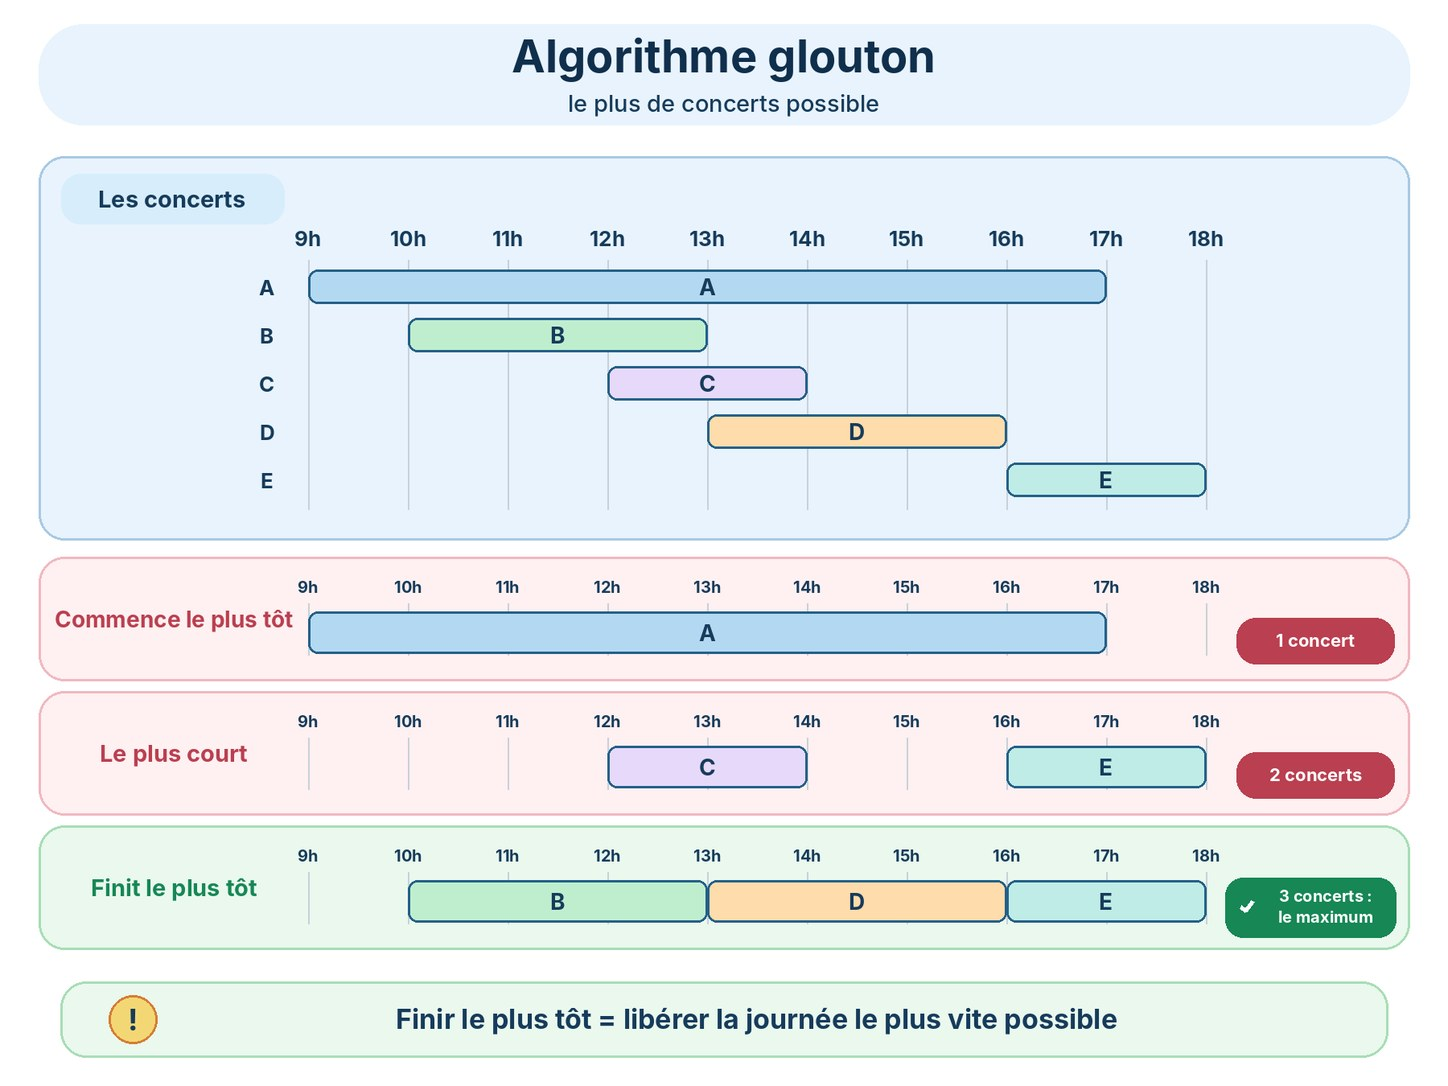

Sur l'image, cinq concerts entre 9 h et 18 h : A (9 h–17 h), B (10 h–13 h), C (12 h–14 h), D (13 h–16 h) et E (16 h–18 h).
- « Commence le plus tôt » choisit A, qui occupe presque toute la journée : **1 concert**.
- « Le plus court » choisit C (2 h), puis E ; mais C chevauche à la fois B et D : **2 concerts**.
- « Finit le plus tôt » choisit B (fini à 13 h), puis D (13 h–16 h), puis E (16 h–18 h) : **3 concerts**, le maximum.

**Pourquoi « finit le plus tôt » est la bonne règle :** choisir le concert qui se termine le plus tôt, c'est **libérer la journée le plus vite possible** pour la suite. Prends n'importe quelle meilleure sélection possible : on peut remplacer son premier concert par celui qui finit le plus tôt, car il finit avant (ou en même temps) et ne gêne donc aucun des concerts suivants. On recommence ensuite le même raisonnement sur le reste de la journée.

In [ ]:
concerts = [("A", 9, 17), ("B", 10, 13), ("C", 12, 14), ("D", 13, 16), ("E", 16, 18)]

def max_concerts(concerts):
    choisis = []
    fin_dernier = 0                                         # heure de fin du dernier concert choisi
    for nom, debut, fin in sorted(concerts, key=lambda c: c[2]):   # celui qui finit le plus tôt d'abord
        if debut >= fin_dernier:                            # il commence après la fin du précédent
            choisis.append(nom)
            fin_dernier = fin
    return choisis

print(max_concerts(concerts))   # ['B', 'D', 'E']

**Trace à la main** (concerts triés par heure de fin) :

| Concert | début – fin | fin du dernier choisi | compatible ? | choisis |
|---|---|---|---|---|
| B | 10 – 13 | 0 | oui | B |
| C | 12 – 14 | 13 | 12 < 13 → non | B |
| D | 13 – 16 | 13 | oui (il commence pile à 13 h) | B, D |
| A | 9 – 17 | 16 | 9 < 16 → non | B, D |
| E | 16 – 18 | 16 | oui | B, D, E |

### Vérifier un glouton : le comparer à la force brute
En test, on n'a pas toujours le temps de **prouver** qu'une règle gloutonne est juste. Mais on peut la **mettre à l'épreuve** :
1. écrire une solution **lente mais forcément juste** (la « force brute ») : ici, essayer tous les groupes de concerts possibles ;
2. comparer les deux solutions sur des centaines de petits cas tirés au hasard.

Si une règle est fausse, on trouve très vite un contre-exemple.

In [ ]:
import random
from itertools import combinations

def max_concerts_force_brute(concerts):
    # Essaie TOUS les groupes, du plus grand au plus petit : lent (2ⁿ groupes), mais forcément juste.
    for taille in range(len(concerts), 0, -1):
        for groupe in combinations(concerts, taille):
            if all(f1 <= d2 or f2 <= d1 for (_, d1, f1), (_, d2, f2) in combinations(groupe, 2)):
                return taille                   # aucun chevauchement dans ce groupe
    return 0

def glouton_selon(concerts, regle):
    # Prend les concerts dans l'ordre donné par la règle, s'ils ne chevauchent aucun concert déjà pris.
    choisis = []
    for nom, debut, fin in sorted(concerts, key=regle):
        if all(fin <= d or f <= debut for _, d, f in choisis):
            choisis.append((nom, debut, fin))
    return len(choisis)

def mettre_a_l_epreuve(regle, essais=500):
    random.seed(0)
    for _ in range(essais):
        festival = []
        for i in range(random.randint(1, 6)):
            debut = random.randint(9, 17)
            festival.append((f"c{i}", debut, debut + random.randint(1, 4)))
        if glouton_selon(festival, regle) != max_concerts_force_brute(festival):
            return f"❌ contre-exemple : {festival}"
    return f"✅ {essais} festivals au hasard : toujours le maximum"

print("commence le plus tôt :", mettre_a_l_epreuve(lambda c: c[1]))
print("le plus court        :", mettre_a_l_epreuve(lambda c: c[2] - c[1]))
print("finit le plus tôt    :", mettre_a_l_epreuve(lambda c: c[2]))

Les deux mauvaises règles sont démasquées : la force brute leur trouve un contre-exemple, que tu peux vérifier à la main. La bonne règle, elle, résiste aux 500 essais. Ce réflexe vaut pour **tous** tes algorithmes, pas seulement les gloutons : une force brute de quelques lignes est le meilleur outil pour tester une solution astucieuse.

### Les règles gloutonnes classiques
| Problème | Règle gloutonne qui marche |
|---|---|
| rendre la monnaie en euros | la plus grosse pièce d'abord (mais pas avec n'importe quelles pièces !) |
| le plus d'activités / de réunions sans chevauchement | celle qui **finit** le plus tôt d'abord |
| le plus de tâches possible avec un budget de temps | les plus **courtes** d'abord |
| satisfaire le plus de demandes avec des ressources de tailles différentes | la plus petite ressource suffisante pour la demande la plus facile |

## Quand y penser ?
- « divisible », « multiple », « reste », « chiffres d'un nombre », « pair / impair » → **`%` et `//`** ;
- « compter sans parcourir », des bornes énormes (10¹², 10¹⁸) → une **formule** avec `//` ;
- « cycle », « circulaire », « tous les `k` jours », « horloge » → **modulo** ;
- « fraction irréductible », « plus grand diviseur commun », « de nouveau en même temps » → **PGCD / PPCM** ;
- « le maximum de… », « le minimum de… » quand un **ordre naturel** se devine (le plus petit, celui qui finit le plus tôt…) → **glouton**, souvent après un tri ;
- un glouton qui a un contre-exemple → **programmation dynamique** (thème 8).

## Les pièges
- `/` renvoie un float : sur de grands entiers, `int(a / b)` peut être faux → utiliser `a // b`.
- Avec des nombres négatifs, `//` arrondit vers le bas : `-7 // 2` vaut `-4`.
- `0` a un chiffre, mais la boucle `while n > 0` n'en trouve aucun.
- Les chiffres extraits avec `% 10` sortent **à l'envers** (de droite à gauche).
- Croire un glouton juste parce qu'il marche sur l'exemple de l'énoncé : cherche un contre-exemple, ou compare-le à une force brute.

## À toi de jouer — le plus d'enfants contents
> Des enfants ont chacun un **appétit** ; des parts de gâteau ont chacune une **taille**. Un enfant est content s'il reçoit une part de taille **supérieure ou égale** à son appétit. Chaque enfant reçoit au plus une part, et chaque part ne peut être donnée qu'une fois.
> Écris `enfants_contents(appetits, parts)` qui renvoie le **nombre maximum** d'enfants contents.
> `enfants_contents([1, 2, 3], [1, 1])` → `1` · `enfants_contents([1, 2], [1, 2, 3])` → `2`

**Indice** : trie les deux listes. Parcours les parts de la plus petite à la plus grande, en gardant l'indice de l'enfant **le moins gourmand** qui n'a encore rien reçu. Si la part lui suffit, il est content : passe à l'enfant suivant. Sinon, cette part est trop petite pour lui… et donc pour tous les autres, plus gourmands : passe à la part suivante.

In [ ]:
def enfants_contents(appetits, parts):
    # À toi de jouer !
    pass

verifier(enfants_contents, [
    (([1, 2, 3], [1, 1]), 1),
    (([1, 2], [1, 2, 3]), 2),
    (([5, 1, 3], [2, 4, 1]), 2),     # les listes ne sont pas triées au départ
    (([10, 9, 8], [1, 2, 3]), 0),    # toutes les parts sont trop petites
    (([3, 3], [3, 3, 3]), 2),        # une part égale à l'appétit suffit
    (([], [1, 2]), 0),
    (([2], []), 0),
])

<details>
<summary><b>Voir la solution</b> (essaie vraiment d'abord !)</summary>

```python
def enfants_contents(appetits, parts):
    appetits = sorted(appetits)
    parts = sorted(parts)
    i = 0                                    # le moins gourmand des enfants qui n'ont rien reçu
    for p in parts:                          # des plus petites parts aux plus grandes
        if i < len(appetits) and p >= appetits[i]:
            i += 1                           # cette part le contente : enfant suivant
        # sinon : part trop petite pour lui, donc pour tous les suivants → on passe
    return i                                 # nombre d'enfants servis

# Deux tris puis un seul passage : O(n log n).
```

</details>

---

**Suite :** [Thème 8 — Programmation dynamique et backtracking](theme8_dp_backtracking.ipynb) ➡ · [Retour au sommaire](00_sommaire.ipynb)

**S'entraîner :** [Série 7 — Mathématiques et algorithmes gloutons](exercices/serie7_maths_gloutons.ipynb) (6 exercices avec tests automatiques)